# Sprint IA07 · Optimización de hiperparámetros — RSU Yarinacocha
**Universidad Nacional de Ingeniería · Maestría en Ciencias con mención en Inteligencia Artificial**  
**Proyecto:** Sistema híbrido de aprendizaje automático y optimización combinatoria para la planificación de rutas de recolección de residuos sólidos urbanos.  
**Autores:** Grimaldo René Abarca Urbano y Jorge Raúl Valega Marquina.

**Alcance:** predicción de `residuos_recolectados_kg` (kg por recorrido) con Random Forest y XGBoost; comparación Random Search vs. optimización bayesiana TPE (Optuna). Se reserva la optimización de rutas (OR-Tools) para una etapa posterior. El notebook anterior predecía `duracion_min`; aquí el objetivo se alinea con la matriz de consistencia.

**Advertencia de procedencia:** el notebook original declara los datos como **simulados**; los resultados son una demostración metodológica, no evidencia de desempeño operacional real. El CSV incluye registros hasta el 31/12/2026, posterior a la fecha de preparación (06/11/2026).

**Criterio:** minimizar MAE (kg). RMSE y R² son métricas complementarias. No usar test para elegir hiperparámetros.

## 0. Instalación y reproducibilidad
Ejecutar de arriba hacia abajo en Google Colab o Jupyter. En Colab, subir `residuos_yarinacocha_2026(2).csv` cuando se solicite. Un equipo local puede colocar el CSV junto al Notebook. Se fija una semilla y se registran archivos en `artifacts/`.

In [1]:
print('Dependencias instaladas. En Google Colab ejecutar: %pip -q install optuna xgboost scikit-learn joblib pyyaml')

Dependencias instaladas. En Google Colab ejecutar: %pip -q install optuna xgboost scikit-learn joblib pyyaml


In [2]:
import os, json, time, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
import optuna, xgboost as xgb, joblib, yaml
from optuna.samplers import RandomSampler, TPESampler
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42
np.random.seed(SEED)
OUT=Path('artifacts'); OUT.mkdir(exist_ok=True)
# Presupuesto sugerido para entrega: 15 trials por combinación (2 modelos × 2 métodos = 60 trials).
# Para un test rápido local: establecer variable de entorno N_TRIALS=2.
N_TRIALS=int(os.environ.get('N_TRIALS','15'))
N_FOLDS=3
assert N_TRIALS>=1
print('Python:',platform.python_version(),'sklearn:',__import__('sklearn').__version__,'XGBoost:',xgb.__version__,'Optuna:',optuna.__version__)
print('Trials por combinación:',N_TRIALS,'; pliegues temporales:',N_FOLDS)

Python: 3.13.5 sklearn: 1.8.0 XGBoost: 3.1.3 Optuna: 4.8.0
Trials por combinación: 15 ; pliegues temporales: 3


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga y auditoría de calidad de datos
Los registros se ordenan por fecha. No se utilizan como predictores `duracion_min`, `distancia_km`, `combustible_l`, `costo_operativo_soles`, `puntos_atendidos`, `cumplimiento_pct`, `hora_llegada` ni `incidencia`, porque son datos observados al terminar el recorrido y podrían producir fuga de información al estimar la demanda antes de la salida.

In [3]:
CANDIDATOS=[Path('residuos_yarinacocha_2026(2).csv'), Path('/mnt/data/residuos_yarinacocha_2026(2).csv'),Path('residuos_yarinacocha_2026.csv')]
ruta=next((p for p in CANDIDATOS if p.exists()),None)
if ruta is None:
    try:
        from google.colab import files
        archivos=files.upload()
        ruta=Path(next(iter(archivos)))
    except ImportError:
        raise FileNotFoundError('Coloca el CSV junto al notebook y ejecuta nuevamente.')
df=pd.read_csv(ruta)
assert 'residuos_recolectados_kg' in df.columns and 'fecha' in df.columns
print('Dimensiones originales:',df.shape,'; duplicados:',df.duplicated().sum())
display(df.isna().sum().to_frame('Valores faltantes'))
df['fecha']=pd.to_datetime(df['fecha'], errors='coerce')
df['residuos_recolectados_kg']=pd.to_numeric(df['residuos_recolectados_kg'],errors='coerce')
df=df.drop_duplicates().dropna(subset=['fecha','residuos_recolectados_kg']).sort_values('fecha',kind='stable').reset_index(drop=True)
print('Registros válidos:',len(df),'; fechas:',df.fecha.min().date(),'a',df.fecha.max().date())
assert df['fecha'].is_monotonic_increasing
assert len(df)>100
print('Variable objetivo (kg):');display(df.residuos_recolectados_kg.describe().to_frame().T)

Dimensiones originales: (733, 18) ; duplicados: 3


,Valores faltantes
fecha,0
codigo_ruta,0
vehiculo,0
sector,0
hora_salida,0
hora_llegada,0
duracion_min,0
distancia_km,0
combustible_l,6
costo_operativo_soles,4


Registros válidos: 730 ; fechas: 2026-01-01 a 2026-12-31
Variable objetivo (kg):


,count,mean,std,min,25%,50%,75%,max
residuos_recolectados_kg,730.0,3833.594014,476.909568,2453.53,3519.4675,3826.035,4140.9175,5352.75


## 2. EDA y generación de atributos disponibles antes del servicio
Se calculan indicadores temporales y de programación; las imputaciones se ajustan solo con el conjunto de entrenamiento de cada fold mediante un `Pipeline`.

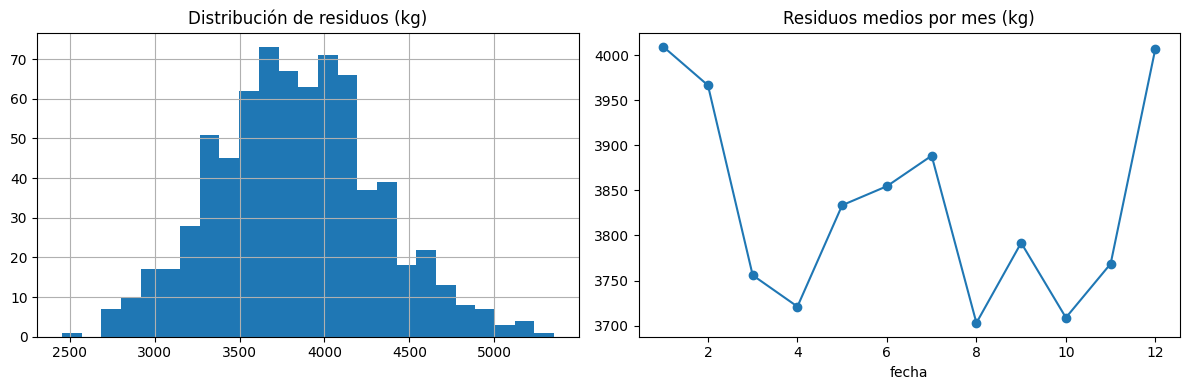

Atributos seleccionados: ['codigo_ruta', 'vehiculo', 'sector', 'capacidad_vehicular_kg', 'puntos_programados', 'mes', 'dia_semana', 'dia_anio', 'fin_semana', 'hora_salida_min', 'hora_sin', 'hora_cos', 'puntos_por_ton_cap']


In [4]:
def preparar_features(data):
    d=data.copy()
    d['mes']=d.fecha.dt.month
    d['dia_semana']=d.fecha.dt.dayofweek
    d['dia_anio']=d.fecha.dt.dayofyear
    d['fin_semana']=(d['dia_semana']>=5).astype('int8')
    h=pd.to_datetime(d['hora_salida'].astype(str),format='%H:%M',errors='coerce')
    d['hora_salida_min']=h.dt.hour*60+h.dt.minute
    d['hora_sin']=np.sin(2*np.pi*d['hora_salida_min']/1440)
    d['hora_cos']=np.cos(2*np.pi*d['hora_salida_min']/1440)
    d['puntos_por_ton_cap']=d['puntos_programados']/(d['capacidad_vehicular_kg']/1000).replace(0,np.nan)
    return d
D=preparar_features(df)
fig,ax=plt.subplots(1,2,figsize=(12,4))
D['residuos_recolectados_kg'].hist(bins=25,ax=ax[0]); ax[0].set_title('Distribución de residuos (kg)')
D.groupby(D.fecha.dt.month)['residuos_recolectados_kg'].mean().plot(marker='o',ax=ax[1]);ax[1].set_title('Residuos medios por mes (kg)')
plt.tight_layout();plt.show()
CAT=['codigo_ruta','vehiculo','sector']
NUM=['capacidad_vehicular_kg','puntos_programados','mes','dia_semana','dia_anio','fin_semana','hora_salida_min','hora_sin','hora_cos','puntos_por_ton_cap']
FEATURES=CAT+NUM
TARGET='residuos_recolectados_kg'
assert set(FEATURES).issubset(D.columns)
print('Atributos seleccionados:',FEATURES)

## 3. Partición temporal 70 / 15 / 15
Se separan **fechas únicas** cronológicamente, para evitar que una misma fecha figure en subconjuntos distintos. El test permanece intocable hasta la evaluación final; el entrenamiento se utiliza para la búsqueda con `TimeSeriesSplit`, y la validación se utiliza para la elección del método/modelo ganador.

In [5]:
fechas=np.sort(D['fecha'].unique())
c1,c2=int(.70*len(fechas)),int(.85*len(fechas))
train=D[D.fecha.isin(fechas[:c1])].copy()
val=D[D.fecha.isin(fechas[c1:c2])].copy()
test=D[D.fecha.isin(fechas[c2:])].copy()
assert train.fecha.max()<val.fecha.min() and val.fecha.max()<test.fecha.min()
print('Train',len(train),str(train.fecha.min().date()),str(train.fecha.max().date()))
print('Val  ',len(val),str(val.fecha.min().date()),str(val.fecha.max().date()))
print('Test ',len(test),str(test.fecha.min().date()),str(test.fecha.max().date()))
# CV dentro del tramo de train: pliegues separados por fecha.
train_dates=np.sort(train.fecha.unique())
tss=TimeSeriesSplit(n_splits=N_FOLDS)
CV_SPLITS=[]
for tr_days,va_days in tss.split(train_dates):
    tr_idx=np.flatnonzero(train.fecha.isin(train_dates[tr_days]).to_numpy())
    va_idx=np.flatnonzero(train.fecha.isin(train_dates[va_days]).to_numpy())
    CV_SPLITS.append((tr_idx,va_idx))
    assert train.iloc[tr_idx].fecha.max()<train.iloc[va_idx].fecha.min()
print('CV temporal folds:',[(len(a),len(b)) for a,b in CV_SPLITS])

Train 510 2026-01-01 2026-09-12
Val   110 2026-09-13 2026-11-06
Test  110 2026-11-07 2026-12-31
CV temporal folds: [(132, 126), (258, 126), (384, 126)]


## 4. Pipeline de preprocesamiento y modelos baseline
Comparación consistente, con el mismo split y los mismos predictores. Se almacenan las métricas en validación. Las columnas redundantes `codigo_ruta` y `sector` se conservan para demostrar el tratamiento de categóricas, pero su relación uno-a-uno puede simplificarse en un análisis posterior.

In [6]:
def preprocesador():
    return ColumnTransformer([
        ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),
                         ('ohe',OneHotEncoder(handle_unknown='ignore'))]),CAT),
        ('num',SimpleImputer(strategy='median'),NUM)
    ])
def modelo(nombre,params=None):
    params={} if params is None else dict(params)
    if nombre=='RF':
        base=RandomForestRegressor(random_state=SEED,n_jobs=-1,**params)
    elif nombre=='XGB':
        base=xgb.XGBRegressor(objective='reg:squarederror',random_state=SEED,n_jobs=1,tree_method='hist',**params)
    else:raise ValueError(nombre)
    return Pipeline([('pre',preprocesador()),('reg',base)])
def metricas(real,pred):
    return {'MAE':float(mean_absolute_error(real,pred)),
            'RMSE':float(np.sqrt(mean_squared_error(real,pred))),
            'R2':float(r2_score(real,pred))}
BASE_PARAMS={'RF':{'n_estimators':150,'max_depth':12,'min_samples_leaf':3},
             'XGB':{'n_estimators':150,'max_depth':5,'learning_rate':0.07,'subsample':0.9,'colsample_bytree':0.9}}
baselines=[]
for nombre in ['RF','XGB']:
    start=time.perf_counter();p=modelo(nombre,BASE_PARAMS[nombre]);p.fit(train[FEATURES],train[TARGET]);pred=p.predict(val[FEATURES])
    baselines.append({'modelo':nombre,'metodo':'Baseline','tiempo_s':time.perf_counter()-start,**metricas(val[TARGET],pred)})
baseline_df=pd.DataFrame(baselines)
display(baseline_df.round(3))

,modelo,metodo,tiempo_s,MAE,RMSE,R2
0,RF,Baseline,0.193,324.387,410.076,0.191
1,XGB,Baseline,0.059,353.817,437.825,0.078


## 5. Espacio de búsqueda, presupuesto y función objetivo
Se minimiza el **MAE promedio de 3 folds temporales** sobre el 70 % inicial. Los dos buscadores usan exactamente el mismo espacio, particiones y semilla. La estrategia bayesiana TPE puede adaptarse tras observar pruebas anteriores; RandomSampler no.

**Presupuesto por defecto:** 15 trials × 2 modelos × 2 métodos, 3 folds por trial. Los tiempos dependen del entorno. El registro guarda métricas y duración. Para árboles de sklearn, Optuna no puede hacer pruning intermedio sin integración específica; se emplea poda mediante `trial.report()` sobre folds completos en lugar de early stopping interno. XGBoost se ajusta con un número finito de estimadores; el pruning detiene pruebas desfavorables entre folds.

In [7]:
def buscar_params(trial,nombre):
    if nombre=='RF':
        return {'n_estimators':trial.suggest_int('n_estimators',80,250,step=10),
                'max_depth':trial.suggest_int('max_depth',3,16),
                'min_samples_split':trial.suggest_int('min_samples_split',2,12),
                'min_samples_leaf':trial.suggest_int('min_samples_leaf',1,8),
                'max_features':trial.suggest_categorical('max_features',['sqrt',0.7,1.0])}
    return {'n_estimators':trial.suggest_int('n_estimators',80,280,step=20),
            'max_depth':trial.suggest_int('max_depth',2,9),
            'learning_rate':trial.suggest_float('learning_rate',0.01,0.2,log=True),
            'subsample':trial.suggest_float('subsample',0.6,1.0),
            'colsample_bytree':trial.suggest_float('colsample_bytree',0.6,1.0),
            'min_child_weight':trial.suggest_float('min_child_weight',1,10)}
def funcion_objetivo(nombre):
    def objective(trial):
        params=buscar_params(trial,nombre)
        errores=[]
        for i,(idx_tr,idx_va) in enumerate(CV_SPLITS):
            m=modelo(nombre,params)
            m.fit(train.iloc[idx_tr][FEATURES],train.iloc[idx_tr][TARGET])
            pred=m.predict(train.iloc[idx_va][FEATURES])
            errores.append(mean_absolute_error(train.iloc[idx_va][TARGET],pred))
            trial.report(float(np.mean(errores)),step=i)
            if trial.should_prune():
                trial.set_user_attr('folds_completed',i+1)
                raise optuna.TrialPruned()
        trial.set_user_attr('metric_std',float(np.std(errores)))
        trial.set_user_attr('folds_completed',len(errores))
        return float(np.mean(errores))
    return objective
config={'semilla':SEED,'split':'fechas únicas cronológicas 70/15/15','cv':'TimeSeriesSplit(n_splits=3) sobre train',
        'metrica_objetivo':'MAE en kg (minimizar)','trials_por_combinacion':N_TRIALS,
        'modelos':['RF','XGB'],'metodos':['RandomSampler','TPESampler'],
        'variable_objetivo':TARGET,'atributos':FEATURES,
        'nota':'Datos declarados simulados en el notebook original'}
with open(OUT/'search_config.yaml','w',encoding='utf-8') as f:yaml.safe_dump(config,f,allow_unicode=True,sort_keys=False)
print(yaml.safe_dump(config,allow_unicode=True,sort_keys=False))

semilla: 42
split: fechas únicas cronológicas 70/15/15
cv: TimeSeriesSplit(n_splits=3) sobre train
metrica_objetivo: MAE en kg (minimizar)
trials_por_combinacion: 15
modelos:
- RF
- XGB
metodos:
- RandomSampler
- TPESampler
variable_objetivo: residuos_recolectados_kg
atributos:
- codigo_ruta
- vehiculo
- sector
- capacidad_vehicular_kg
- puntos_programados
- mes
- dia_semana
- dia_anio
- fin_semana
- hora_salida_min
- hora_sin
- hora_cos
- puntos_por_ton_cap
nota: Datos declarados simulados en el notebook original



## 6. Ejecutar búsqueda Random y Bayes (TPE)
Los estudios registran la historia de trials y las configuraciones. El pruner usa una fase inicial de calentamiento para no detener todos los primeros ensayos. La existencia de trials podados depende de los resultados, no está garantizada.

In [8]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
estudios={}; filas=[]
for nombre in ['RF','XGB']:
    for metodo in ['Random','Bayes_TPE']:
        sampler=RandomSampler(seed=SEED) if metodo=='Random' else TPESampler(seed=SEED,n_startup_trials=min(5,max(1,N_TRIALS//3)))
        pruner=optuna.pruners.MedianPruner(n_startup_trials=min(5,max(1,N_TRIALS//3)),n_warmup_steps=1)
        study=optuna.create_study(direction='minimize',sampler=sampler,pruner=pruner,study_name=f'{nombre}_{metodo}')
        t0=time.perf_counter()
        study.optimize(funcion_objetivo(nombre),n_trials=N_TRIALS,show_progress_bar=False)
        estudios[(nombre,metodo)]=study
        for t in study.trials:
            filas.append({'modelo':nombre,'metodo':metodo,'trial_id':t.number,
                          'estado':t.state.name,'params':json.dumps(t.params,ensure_ascii=False),
                          'seed':SEED,'split_cfg':'temporal 70/15/15; CV 3 folds',
                          'metric_mean_MAE':t.value if t.value is not None else np.nan,
                          'metric_std_MAE':t.user_attrs.get('metric_std',np.nan),
                          'folds_completed':t.user_attrs.get('folds_completed',np.nan),
                          'tiempo_s':t.duration.total_seconds() if t.duration is not None else np.nan})
        if len(study.get_trials(states=[optuna.trial.TrialState.COMPLETE])):
            print(nombre,metodo,'mejor CV MAE:',round(study.best_value,3),'kg; duración:',round(time.perf_counter()-t0,1),'s')
logs=pd.DataFrame(filas)
logs.to_csv(OUT/'hpo_runs.csv',index=False)
display(logs.sort_values('metric_mean_MAE').head(10).round(3))
print('Pruebas registradas:',len(logs),'— completadas:',sum(logs.estado=='COMPLETE'),'— podadas:',sum(logs.estado=='PRUNED'))

RF Random mejor CV MAE: 300.754 kg; duración: 6.5 s


RF Bayes_TPE mejor CV MAE: 299.489 kg; duración: 8.9 s


XGB Random mejor CV MAE: 300.701 kg; duración: 1.7 s


XGB Bayes_TPE mejor CV MAE: 300.701 kg; duración: 2.1 s


,modelo,metodo,trial_id,estado,params,seed,split_cfg,metric_mean_MAE,metric_std_MAE,folds_completed,tiempo_s
53,XGB,Bayes_TPE,8,PRUNED,"{""n_estimators"": 220, ""max_depth"": 4, ""learnin...",42,temporal 70/15/15; CV 3 folds,297.471,NaN,2,0.110
27,RF,Bayes_TPE,12,COMPLETE,"{""n_estimators"": 170, ""max_depth"": 14, ""min_sa...",42,temporal 70/15/15; CV 3 folds,299.489,14.975,3,0.611
36,XGB,Random,6,PRUNED,"{""n_estimators"": 140, ""max_depth"": 2, ""learnin...",42,temporal 70/15/15; CV 3 folds,300.340,NaN,2,0.043
37,XGB,Random,7,PRUNED,"{""n_estimators"": 80, ""max_depth"": 9, ""learning...",42,temporal 70/15/15; CV 3 folds,300.512,NaN,2,0.068
32,XGB,Random,2,COMPLETE,"{""n_estimators"": 260, ""max_depth"": 3, ""learnin...",42,temporal 70/15/15; CV 3 folds,300.701,18.077,3,0.111
47,XGB,Bayes_TPE,2,COMPLETE,"{""n_estimators"": 260, ""max_depth"": 3, ""learnin...",42,temporal 70/15/15; CV 3 folds,300.701,18.077,3,0.110
1,RF,Random,1,COMPLETE,"{""n_estimators"": 230, ""max_depth"": 11, ""min_sa...",42,temporal 70/15/15; CV 3 folds,300.754,15.868,3,0.781
16,RF,Bayes_TPE,1,COMPLETE,"{""n_estimators"": 230, ""max_depth"": 11, ""min_sa...",42,temporal 70/15/15; CV 3 folds,300.754,15.868,3,0.778
26,RF,Bayes_TPE,11,COMPLETE,"{""n_estimators"": 150, ""max_depth"": 13, ""min_sa...",42,temporal 70/15/15; CV 3 folds,300.896,14.542,3,0.535
57,XGB,Bayes_TPE,12,PRUNED,"{""n_estimators"": 120, ""max_depth"": 6, ""learnin...",42,temporal 70/15/15; CV 3 folds,301.002,NaN,2,0.099


Pruebas registradas: 60 — completadas: 36 — podadas: 24


## 7. Validación externa y elección de la configuración ganadora
Se ajusta en el subconjunto de entrenamiento cada configuración optimizada, y se evalúa en el 15 % de validación. Se selecciona el menor MAE de validación. El test no participa en esta selección.

In [9]:
comparacion=list(baselines)
candidatos={}
for (nombre,metodo),study in estudios.items():
    if not study.get_trials(states=[optuna.trial.TrialState.COMPLETE]):continue
    params=study.best_params
    m=modelo(nombre,params)
    start=time.perf_counter();m.fit(train[FEATURES],train[TARGET])
    metrics=metricas(val[TARGET],m.predict(val[FEATURES]))
    k=(nombre,metodo);candidatos[k]=(params,metrics)
    comparacion.append({'modelo':nombre,'metodo':metodo,'tiempo_s':time.perf_counter()-start,
                        'CV_MAE':study.best_value,'CV_STD':study.best_trial.user_attrs.get('metric_std',np.nan),**metrics})
comp=pd.DataFrame(comparacion).sort_values('MAE').reset_index(drop=True)
display(comp.round(3))
ganadora=comp.iloc[0]
nombre_ganador=str(ganadora['modelo']);metodo_ganador=str(ganadora['metodo'])
params_ganadores=BASE_PARAMS[nombre_ganador] if metodo_ganador=='Baseline' else candidatos[(nombre_ganador,metodo_ganador)][0]
print('GANADORA:',nombre_ganador,metodo_ganador,'— MAE validación:',round(ganadora.MAE,3),'kg')
print('Parámetros:',params_ganadores)
comp.to_csv(OUT/'comparacion_validacion.csv',index=False)
with open(OUT/'config_ganadora.json','w',encoding='utf-8') as f:
    json.dump({'modelo':nombre_ganador,'metodo':metodo_ganador,'parametros':params_ganadores,
               'MAE_validacion_kg':float(ganadora.MAE),'semilla':SEED},f,ensure_ascii=False,indent=2)

,modelo,metodo,tiempo_s,MAE,RMSE,R2,CV_MAE,CV_STD
0,RF,Random,0.301,317.336,399.301,0.233,300.754,15.868
1,XGB,Random,0.052,318.927,399.869,0.231,300.701,18.077
2,XGB,Bayes_TPE,0.048,318.927,399.869,0.231,300.701,18.077
3,RF,Bayes_TPE,0.238,322.244,408.305,0.198,299.489,14.975
4,RF,Baseline,0.193,324.387,410.076,0.191,NaN,NaN
5,XGB,Baseline,0.059,353.817,437.825,0.078,NaN,NaN


GANADORA: RF Random — MAE validación: 317.336 kg
Parámetros: {'n_estimators': 230, 'max_depth': 11, 'min_samples_split': 9, 'min_samples_leaf': 1, 'max_features': 'sqrt'}


## 8. Tabla top-k y evolución
La tabla incluye trials completos con media ± desviación estándar del MAE de validación cruzada. Los gráficos muestran la métrica según el número de prueba y la comparación de MAE del holdout de validación.

,modelo,metodo,trial_id,params,MAE media ± DE,tiempo_s
27,RF,Bayes_TPE,12,"{""n_estimators"": 170, ""max_depth"": 14, ""min_sa...",299.49 ± 14.97 kg,0.611278
32,XGB,Random,2,"{""n_estimators"": 260, ""max_depth"": 3, ""learnin...",300.70 ± 18.08 kg,0.111231
47,XGB,Bayes_TPE,2,"{""n_estimators"": 260, ""max_depth"": 3, ""learnin...",300.70 ± 18.08 kg,0.110273
1,RF,Random,1,"{""n_estimators"": 230, ""max_depth"": 11, ""min_sa...",300.75 ± 15.87 kg,0.780777
16,RF,Bayes_TPE,1,"{""n_estimators"": 230, ""max_depth"": 11, ""min_sa...",300.75 ± 15.87 kg,0.777697
26,RF,Bayes_TPE,11,"{""n_estimators"": 150, ""max_depth"": 13, ""min_sa...",300.90 ± 14.54 kg,0.534750
28,RF,Bayes_TPE,13,"{""n_estimators"": 180, ""max_depth"": 14, ""min_sa...",301.27 ± 14.68 kg,0.608816
56,XGB,Bayes_TPE,11,"{""n_estimators"": 180, ""max_depth"": 6, ""learnin...",302.28 ± 15.49 kg,0.247667
24,RF,Bayes_TPE,9,"{""n_estimators"": 150, ""max_depth"": 13, ""min_sa...",302.32 ± 15.94 kg,0.533581
39,XGB,Random,9,"{""n_estimators"": 200, ""max_depth"": 9, ""learnin...",302.40 ± 14.62 kg,0.222369


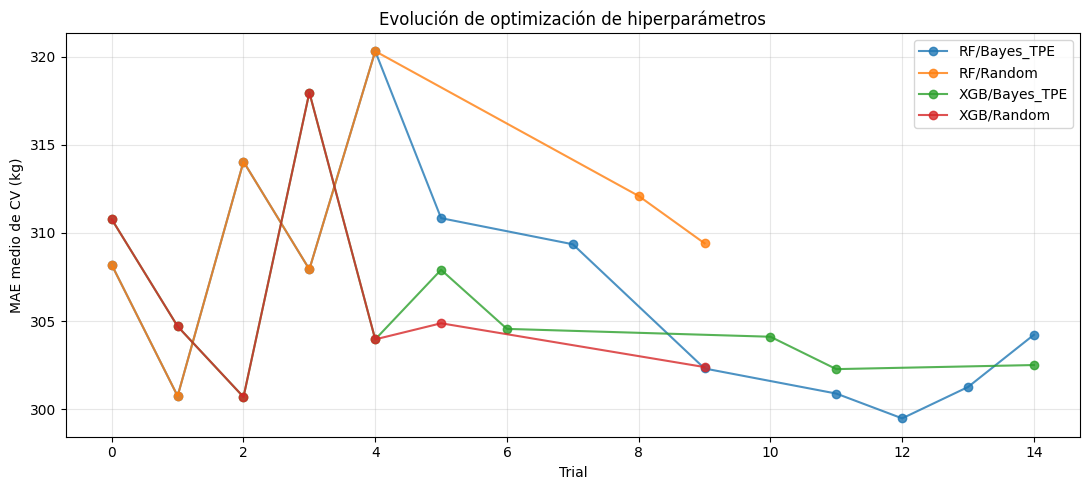

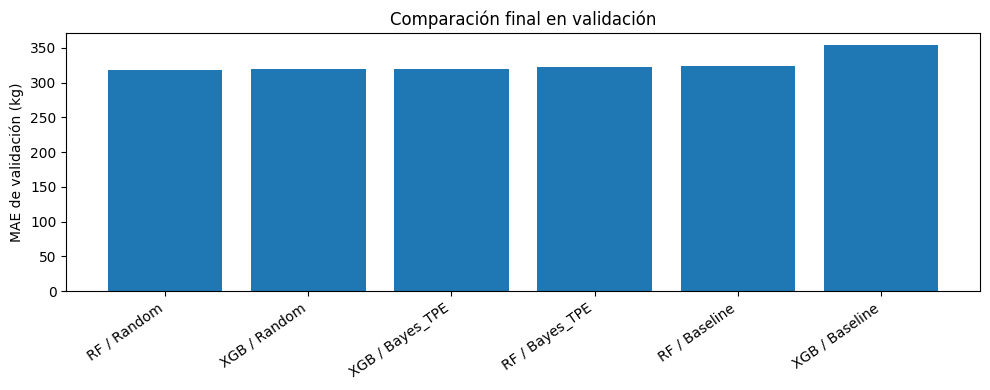

In [10]:
top=logs[logs.estado=='COMPLETE'].nsmallest(10,'metric_mean_MAE').copy()
top['MAE media ± DE']=top.apply(lambda x:f"{x.metric_mean_MAE:.2f} ± {x.metric_std_MAE:.2f} kg",axis=1)
display(top[['modelo','metodo','trial_id','params','MAE media ± DE','tiempo_s']])
fig,ax=plt.subplots(figsize=(11,5))
for (nom,met),grp in logs[logs.estado=='COMPLETE'].groupby(['modelo','metodo']):
    grp=grp.sort_values('trial_id');ax.plot(grp.trial_id,grp.metric_mean_MAE,marker='o',label=f'{nom}/{met}',alpha=.8)
ax.set(xlabel='Trial',ylabel='MAE medio de CV (kg)',title='Evolución de optimización de hiperparámetros');ax.legend();ax.grid(alpha=.3)
plt.tight_layout();plt.savefig(OUT/'evolucion_trials.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(comp.modelo+' / '+comp.metodo,comp.MAE)
ax.set(ylabel='MAE de validación (kg)',title='Comparación final en validación');plt.xticks(rotation=35,ha='right');plt.tight_layout();plt.savefig(OUT/'comparacion_mae.png',dpi=160);plt.show()

## 9. Evaluación única sobre test y modelo exportado
Luego de fijar la elección a partir de validación, se reentrena la configuración seleccionada con train + validación y se mide una sola vez en el tramo final de test. Esta evaluación no debe utilizarse para volver a elegir el modelo.

Test temporal (evaluación única): {'MAE': 366.7141913731075, 'RMSE': 458.67203669114826, 'R2': -0.007470259537831536} ; tiempo ajuste 0.32 s


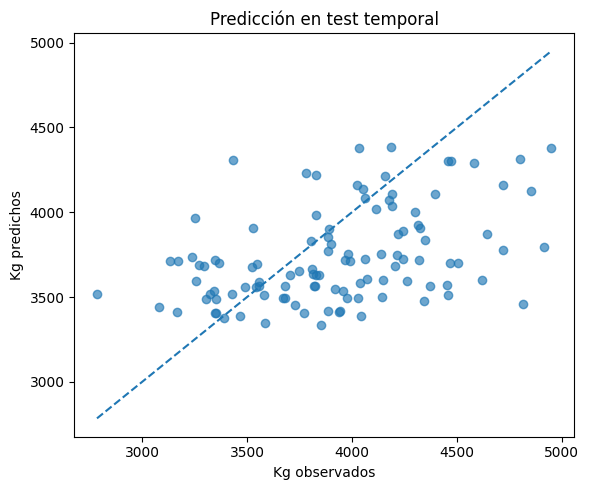

In [11]:
train_val=pd.concat([train,val],ignore_index=True).sort_values('fecha',kind='stable')
final=modelo(nombre_ganador,params_ganadores)
t0=time.perf_counter();final.fit(train_val[FEATURES],train_val[TARGET]);pred_test=final.predict(test[FEATURES])
resultado_test=metricas(test[TARGET],pred_test)
print('Test temporal (evaluación única):',resultado_test,'; tiempo ajuste',round(time.perf_counter()-t0,2),'s')
pd.DataFrame([{'modelo':nombre_ganador,'metodo':metodo_ganador,**resultado_test}]).to_csv(OUT/'metricas_test.csv',index=False)
joblib.dump({'pipeline':final,'features':FEATURES,'target':TARGET,'seed':SEED},OUT/'modelo_predictivo.joblib')
fig,ax=plt.subplots(figsize=(6,5));ax.scatter(test[TARGET],pred_test,alpha=.65)
lim=[min(test[TARGET].min(),pred_test.min()),max(test[TARGET].max(),pred_test.max())]
ax.plot(lim,lim,'--');ax.set(xlabel='Kg observados',ylabel='Kg predichos',title='Predicción en test temporal')
plt.tight_layout();plt.savefig(OUT/'predicciones_test.png',dpi=160);plt.show()

## 10. Interpretación, limitaciones y próximos pasos

**Qué se demuestra:** auditoría y procesamiento de datos, baseline de dos algoritmos, definición explícita del espacio de búsqueda, presupuesto de trials, validación temporal, búsqueda Random/TPE, registro de logs, tabla top-k, selección justificada y test reservado.

**Limitaciones:** el archivo original declara los datos como simulados; una buena métrica aquí **no valida** su aplicación a las rutas reales. Los registros representan **recorridos**, no demandas por punto; el siguiente sprint requiere puntos georreferenciados, matriz vial de distancias/tiempos, capacidades, ventanas horarias y restricciones para OR-Tools. La predicción de kilogramos recolectados puede reflejar capacidad operativa además de demanda; se necesitará comprobar esa distinción con datos reales.

**Archivos producidos:** `artifacts/search_config.yaml`, `hpo_runs.csv`, `comparacion_validacion.csv`, `config_ganadora.json`, `metricas_test.csv`, `modelo_predictivo.joblib`, tres PNG. Subir el notebook, el CSV (si se permite compartirlo), los logs, la configuración y los gráficos al repositorio GitHub, excluyendo datos sensibles.

In [12]:
# En Google Colab: descarga opcional de todos los artefactos de forma compacta
import shutil
paquete=shutil.make_archive('artefactos_sprint_IA07','zip',root_dir='artifacts')
print('Archivos generados:',sorted(p.name for p in OUT.iterdir()))
print('ZIP:',paquete)
# Para descargar en Colab, descomentar:
# from google.colab import files
# files.download(paquete)

Archivos generados: ['comparacion_mae.png', 'comparacion_validacion.csv', 'config_ganadora.json', 'evolucion_trials.png', 'hpo_runs.csv', 'metricas_test.csv', 'modelo_predictivo.joblib', 'predicciones_test.png', 'search_config.yaml']
ZIP: /mnt/data/artefactos_sprint_IA07.zip
